# Tarea: repaso de la distribución predictiva
### Estadística para IA, Concentración en IA, Tec de Monterrey

Esta tarea es de **repaso y refuerzo**. El código ya está escrito casi en su totalidad: su trabajo es correrlo, cambiar uno que otro número cuando se les pida, y sobre todo **pensar**. Las preguntas son de interpretación e intuición, y se contestan en las celdas marcadas *Tu respuesta*.

Igual que en las tareas anteriores, me interesa más su argumento que su conclusión. Una respuesta corta y precisa vale más que un párrafo largo que no dice nada. Cuando una pregunta pida que defiendan una postura, defiéndanla contra la mejor objeción que se les ocurra.

**Cómo está organizada:**

| Parte | Tema |
|---|---|
| 0 | Herramientas (solo correr) |
| 1 | Qué hace la predictiva: dos mundos y una receta |
| 2 | La siguiente tienda: cuando el MLE dice "imposible" |
| 3 | Las siguientes 10 tiendas: *plug-in* contra predictiva |
| 4 | Cuatro gerentes, cuatro priors |
| 5 | ¿Quién predice mejor? Un experimento |
| 6 | Cierre |

**Recordatorio de la sesión.** Si $\tilde y$ es un dato que todavía no observamos,

$$
p(\tilde y\mid\text{datos})=\int p(\tilde y\mid\theta)\;p(\theta\mid\text{datos})\,d\theta .
$$

En el caso Beta-Binomial, con prior $\text{Beta}(a,b)$, $y$ éxitos en $n$ visitas y $m$ tiendas futuras, la predictiva es una **Beta-Binomial** con parámetros $(m,\;a+y,\;b+n-y)$.


## Parte 0. funciones y demás herramientas

Corran estas dos celdas. No hay que modificarlas, pero vale la pena leerlas: cada función hace una sola cosa y tiene un nombre que dice cuál.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)

# colores
SLATE, TEAL, WARN, GOLD, GRIS = "#283747", "#169685", "#B03A2E", "#BC8E3A", "#8A8F94"
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:.3f}".format)

In [4]:
def posterior(a, b, y, n):
    """Prior Beta(a, b) y y éxitos en n visitas: posterior Beta(a + y, b + n - y)."""
    return a + y, b + n - y


def predictiva_bayes(m, a, b, y, n):
    """Predictiva posterior del número de éxitos en m tiendas futuras (Beta-Binomial)."""
    ap, bp = posterior(a, b, y, n)
    return stats.betabinom(m, ap, bp)


def predictiva_plugin(m, theta_hat):
    """Plug-in: fingir que theta_hat es la verdad. Binomial(m, theta_hat)."""
    return stats.binom(m, theta_hat)


def resumen(dists, cola_baja, cola_alta):
    """Tabla con media, desviación estándar, colas e intervalo central del 80%."""
    filas = []
    for nombre, d in dists.items():
        lo, hi = d.ppf(0.10), d.ppf(0.90)
        filas.append({"método": nombre,
                      "media": d.mean(),
                      "desv. est.": d.std(),
                      f"P(≤{cola_baja})": d.cdf(cola_baja),
                      f"P(≥{cola_alta})": d.sf(cola_alta - 1),
                      "intervalo 80%": f"[{lo:.0f}, {hi:.0f}]"})
    return pd.DataFrame(filas).set_index("método")


def graficar(dists, titulo, xlabel="tiendas que aceptan", colores=None):
    """Grafica varias distribuciones discretas sobre 0..m, lado a lado."""
    colores = colores or [GOLD, TEAL, SLATE, WARN, GRIS]
    m = int(list(dists.values())[0].support()[1])
    k = np.arange(m + 1)
    fig, ax = plt.subplots()
    if m <= 20:
        w = 0.8 / len(dists)
        for i, (nombre, d) in enumerate(dists.items()):
            ax.bar(k + (i - (len(dists) - 1) / 2) * w, d.pmf(k), width=w,
                   color=colores[i], label=nombre, alpha=0.9)
        ax.set_xticks(k)
    else:
        for i, (nombre, d) in enumerate(dists.items()):
            ax.plot(k, d.pmf(k), "-o", ms=3, color=colores[i], label=nombre)
    ax.set_title(titulo); ax.set_xlabel(xlabel); ax.set_ylabel("probabilidad")
    if len(dists) >= 4:
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    else:
        ax.legend()
    plt.tight_layout(); plt.show()


def simular_predictiva(a, b, y, n, m, S=100_000, fingir_certeza=False):
    """La receta de dos pasos.
    Paso 1: sacar theta del posterior (o, si fingir_certeza, usar siempre su media).
    Paso 2: con ese theta, simular cuántas de m tiendas aceptan."""
    ap, bp = posterior(a, b, y, n)
    if fingir_certeza:
        theta = np.full(S, ap / (ap + bp))
    else:
        theta = rng.beta(ap, bp, size=S)
    return rng.binomial(m, theta)


def descomponer_varianza(a, b, y, n, m):
    """Ley de la varianza total para la predictiva Beta-Binomial.
    Regresa (parte por el azar del conteo, parte por no saber theta)."""
    ap, bp = posterior(a, b, y, n)
    s = ap + bp
    E_th_1mth = ap * bp / (s * (s + 1))          # E[theta (1 - theta) | datos]
    Var_th = ap * bp / (s ** 2 * (s + 1))        # Var(theta | datos)
    return m * E_th_1mth, m ** 2 * Var_th

print("Listo.")

Listo.



## Parte 1. Qué hace la predictiva?

### 1.1 Dos mundos

Antes de usar fórmulas, el caso más simple posible. Supongan que, después de ver los datos, solo hay dos valores creíbles de $\theta$: **0.5** o **0.8**, cada uno con probabilidad $\tfrac12$. ¿Cuántas de 10 tiendas nuevas van a aceptar?

La predictiva promedia lo que predice cada mundo. El *plug-in* primero promedia los mundos ($\theta=0.65$) y después predice.

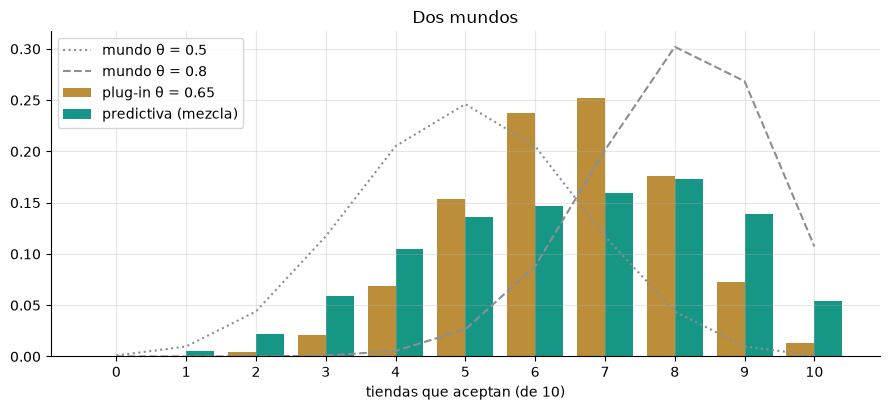

P(las 10 aceptan):   predictiva = 0.054   plug-in = 0.013
P(3 o menos):        predictiva = 0.086   plug-in = 0.026
Medias:              predictiva = 6.50    plug-in = 6.50


In [3]:
k = np.arange(11)
mundo_05 = stats.binom(10, 0.5).pmf(k)
mundo_08 = stats.binom(10, 0.8).pmf(k)
predictiva = 0.5 * mundo_05 + 0.5 * mundo_08          # promediar DESPUÉS de predecir
plugin = stats.binom(10, 0.65).pmf(k)                  # promediar ANTES de predecir

fig, ax = plt.subplots()
ax.plot(k, mundo_05, ":", color=GRIS, label="mundo θ = 0.5")
ax.plot(k, mundo_08, "--", color=GRIS, label="mundo θ = 0.8")
ax.bar(k - 0.2, plugin, width=0.4, color=GOLD, label="plug-in θ = 0.65")
ax.bar(k + 0.2, predictiva, width=0.4, color=TEAL, label="predictiva (mezcla)")
ax.set_xticks(k); ax.set_xlabel("tiendas que aceptan (de 10)"); ax.legend()
ax.set_title("Dos mundos"); plt.tight_layout(); plt.show()

print(f"P(las 10 aceptan):   predictiva = {predictiva[10]:.3f}   plug-in = {plugin[10]:.3f}")
print(f"P(3 o menos):        predictiva = {predictiva[:4].sum():.3f}   plug-in = {plugin[:4].sum():.3f}")
print(f"Medias:              predictiva = {(k * predictiva).sum():.2f}    plug-in = {(k * plugin).sum():.2f}")

**Pregunta 1.1.** Las dos distribuciones tienen la misma media, y sin embargo la predictiva le da a "las 10 aceptan" unas cuatro veces más probabilidad que el *plug-in*. Expliquen, con el lenguaje de los dos mundos, de dónde sale esa probabilidad extra. ¿Qué mundo "alimenta" cada cola?

**Tu respuesta:** 

El parámetro utilizado para el plug-in vive en un mundo "ideal", ficticio, se aleja de los dos parámetros reales porque no existe en el fenómeno observado, se acerca, sí, pero no es parte de. En cambio, la  predictiva sí toma en cuenta los dos mundos y les da mitad y mitad, por lo que aumenta su similitud a ambos, pues los usa directamente como criterio. Por ejemplo, la cola alta en la probabilidad de que acepten las 10 está dado por los valores observados para el parámetro 0.8 y la cola baja en 3 o menos se ve afectada por este mismo parámetro porque no existe o es extremadamente bajo e influye bastante en cómo se representa. 

**Pregunta 1.2.** La predictiva (verde) es mucho más ancha y aplanada que cualquiera de los dos mundos por separado. ¿Por qué? ¿Qué tendría que pasar con los dos mundos para que la predictiva se pareciera mucho al *plug-in*? (Piensen en qué pasa si los mundos se acercan entre sí, o si uno de los dos se vuelve mucho más creíble que el otro.)

**Tu respuesta:** 

Es más ancha porque tiene que repartir su probabilidad entre dos mundos que están lejos uno del otro (0.5 y 0.8). Al cubrir ambos, no se concentra en un solo pico y queda aplanada. Para que se pareciera al plug-in los dos mundos tendrían que acercarse (por ejemplo 0.6 y 0.7) para que la distancia de los valores no tenga tanto peso y termine formando una distribución parecida entre un mundo que ve el promedio de un parámetro y un mundo que ve un promedio general. 


### 1.2 La receta de dos pasos

Volvemos al ejemplo de clase: prior $\text{Beta}(2,2)$, **7 de 10** tiendas aceptaron, posterior $\text{Beta}(9,5)$. La predictiva se puede obtener sin integrar nada, simulando:

1. saco un $\theta$ del posterior;
2. con ese $\theta$, simulo cuántas de 10 tiendas aceptan;
3. repito muchas veces.

La celda compara la simulación con la fórmula exacta (Beta-Binomial). La opción `fingir_certeza=True` hace trampa en el paso 1: siempre usa la media posterior.

In [5]:
a, b, y, n, m = 2, 2, 7, 10, 10

sim_honesta = simular_predictiva(a, b, y, n, m)
sim_tramposa = simular_predictiva(a, b, y, n, m, fingir_certeza=True)

k = np.arange(m + 1)
exacta = predictiva_bayes(m, a, b, y, n).pmf(k)
frec_honesta = np.bincount(sim_honesta, minlength=m + 1) / len(sim_honesta)
frec_tramposa = np.bincount(sim_tramposa, minlength=m + 1) / len(sim_tramposa)

tabla = pd.DataFrame({"fórmula Beta-Binomial": exacta,
                      "simulación honesta": frec_honesta,
                      "simulación con trampa": frec_tramposa}, index=k)
print(tabla.to_string(float_format="%.4f"))
print(f"\nVarianza:  honesta = {sim_honesta.var():.2f}   con trampa = {sim_tramposa.var():.2f}")

    fórmula Beta-Binomial  simulación honesta  simulación con trampa
0                  0.0009              0.0008                 0.0001
1                  0.0056              0.0053                 0.0006
2                  0.0195              0.0196                 0.0047
3                  0.0476              0.0477                 0.0230
4                  0.0909              0.0907                 0.0732
5                  0.1417              0.1440                 0.1628
6                  0.1837              0.1805                 0.2425
7                  0.1969              0.1992                 0.2471
8                  0.1687              0.1681                 0.1668
9                  0.1062              0.1058                 0.0675
10                 0.0382              0.0383                 0.0117

Varianza:  honesta = 3.67   con trampa = 2.28


**Pregunta 1.3.** La simulación honesta coincide con la fórmula, salvo por ruido en el tercer decimal. ¿Por qué tiene que coincidir? Expliquen qué parte de la integral corresponde al paso 1 y qué parte al paso 2. Y ese ruido en el tercer decimal, ¿es incertidumbre sobre $\theta$ o es otra cosa? (Pista: ¿qué le pasaría si en lugar de 100,000 simulaciones hicieran 100 millones?)

**Tu respuesta:**

La simulación hace dos cosas: primero elige un valor de θ del posterior y después simula cuántas tiendas aceptan. Repite esto muchas veces para obtener la distribución predictiva. La Beta-Binomial hace lo mismo, pero directamente con una fórmula, solo matemáticas. Por eso ambas llegan al mismo resultado, solo que una lo simula y la otra lo calcula. La diferencia en el tercer decimal  puede ser gracias a pequeñas variaciones aleatorias de la simulación. Esto se relaciona con la ley de los grandes números, ya que, mientras más iteraciones se hagan, más se acercará el resultado al valor calculado con la fórmula.

**Pregunta 1.4.** La "simulación con trampa" es exactamente el *plug-in*. Su varianza es menor. ¿Qué fuente de incertidumbre eliminó la trampa, y cuál sobrevivió? Respondan con una frase para cada una.

**Tu respuesta:**

Lo que se eliminó fue la incertidumbre del posterior sobre el valor real de θ. Al usar siempre la media posterior en lugar de considerar todos los valores posibles de θ, es como si ya conociéramos la tasa de aceptación. Por eso, la distribución se vuelve más estrecha y las colas casi desaparecen. Lo que se mantiene es la incertidumbre del conteo: aunque conociéramos θ, las 10 tiendas todavía pueden aceptar o rechazar al azar. Por eso la varianza no es cero, ya que sigue existiendo incertidumbre sobre el resultado.

### 1.3 La predictiva previa

Si en el paso 1 saco $\theta$ del **prior** en lugar del posterior, obtengo lo que el modelo espera ver *antes* de los datos. Un truco: con $y=0$ y $n=0$ el posterior es el prior.

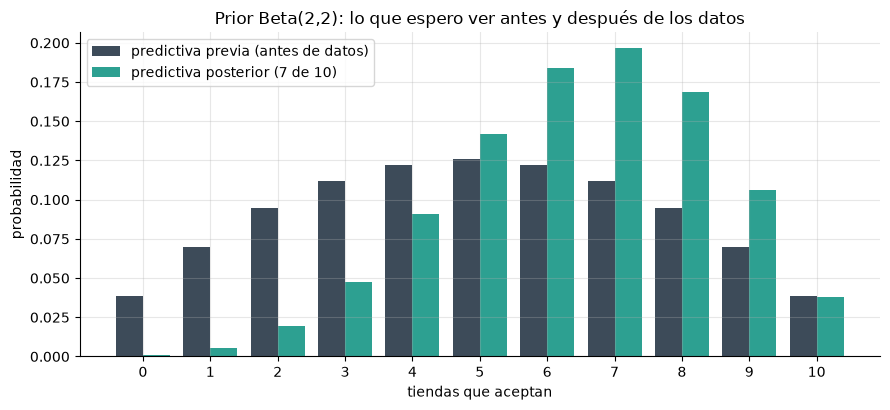

In [6]:
a, b, m = 2, 2, 10
previa = predictiva_bayes(m, a, b, y=0, n=0)
posterior_pred = predictiva_bayes(m, a, b, y=7, n=10)

graficar({"predictiva previa (antes de datos)": previa,
          "predictiva posterior (7 de 10)": posterior_pred},
         "Prior Beta(2,2): lo que espero ver antes y después de los datos",
         colores=[SLATE, TEAL])

**Pregunta 1.5.** Antes de los datos, el prior $\text{Beta}(2,2)$ reparte la probabilidad de forma muy amplia: ningún resultado entre 0 y 10 aceptaciones baja de 3.8%, y ninguno pasa de 13% (revisen la gráfica). ¿Les parece razonable para un producto nuevo de Arca? ¿Qué le dirían a alguien que asegura que un prior "casi plano" en $\theta$ no tiene ninguna opinión? Noten que lo que miramos aquí son *tiendas que aceptan*, algo que un gerente sí entiende, y no $\theta$.

**Tu respuesta:**

Ambas distribuciones acotan perspectivas diferentes: por un lado, la distribución previa es muy "ingenua", mientras que la distribución posterior se ve afectada por el conocimiento de los datos que hacen que se comporte diferente (se adapta al contexto). Concretamente, la previa no muestra picos extremos y se mantiene sobre ciertos límites (ya mencionados), pues reparte su creencia casi por igual entre 0 y 10 tiendas que aceptan porque no conoce nada sobre el producto y por ende, no se inclina tanto a puntos concretos. En cambio, la posterior, se informa con los datos proporcionados y determina que es poco probable que solo 1 tienda acepte, pero es mucho más probable que 7 o más lo hagan. A alguien que asegura que un prior "casi plano" en θ no tiene ninguna opinión, le diría que sí la tiene, y que se ve mejor en tiendas que en θ: está diciendo "espero ~5 de 10 y no me sorprende casi nada entre 0 y 10". 


## Parte 2. La siguiente tienda

### 2.1 Tres respuestas para la misma pregunta

Siete de diez tiendas aceptaron. ¿Cuál es la probabilidad de que la **siguiente** acepte?

In [7]:
y, n = 7, 10
respuestas = {
    "Frecuentista (plug-in con MLE)": y / n,
    "Bayes, prior uniforme Beta(1,1)": predictiva_bayes(1, 1, 1, y, n).pmf(1),
    "Bayes, prior Beta(2,2)": predictiva_bayes(1, 2, 2, y, n).pmf(1),
}
for k_, v in respuestas.items():
    print(f"{k_:35s} {v:.3f}")

Frecuentista (plug-in con MLE)      0.700
Bayes, prior uniforme Beta(1,1)     0.667
Bayes, prior Beta(2,2)              0.643


**Pregunta 2.1.** Las dos respuestas bayesianas quedan por debajo de 0.7. ¿Por qué? Escriban cada una como un promedio ponderado entre la proporción observada y la media del prior, y digan cuánto "pesa" cada parte.

**Tu respuesta:**

Las dos quedan por debajo de 0.7 porque el prior tiene media 0.5, y al mezclarlo con los datos mueve el resultado hacia abajo. La predictiva es como un promedio entre lo que se observó (0.7) y lo que se creía antes (0.5), y cada parte pesa según cuánto "vale" el prior en visitas. En Beta(1,1) el prior vale como 2 visitas, en Beta(2,2) el prior vale como 4 visitas. Como los datos pesan más (10 visitas), el resultado queda cerca de 0.7, pero no en 0.7 porque el prior nunca se ignora del todo. El plug-in con MLE sí da 0.7 exacto justamente porque ignora el prior por completo.

### 2.2 La tienda perfecta

Un vendedor visitó **3 tiendas** y **las 3 aceptaron**. Comparemos al frecuentista ingenuo con Bayes (prior uniforme), para la siguiente tienda y para las siguientes 10.

In [8]:
y, n, m = 3, 3, 10
mle = y / n
pred1 = predictiva_bayes(1, 1, 1, y, n)
pred10 = predictiva_bayes(m, 1, 1, y, n)
plug10 = predictiva_plugin(m, mle)

print(f"P(la siguiente acepta):             MLE = {mle:.3f}    Bayes = {pred1.pmf(1):.3f}")
print(f"P(al menos 1 de 10 rechaza):        MLE = {1 - plug10.pmf(10):.3f}    Bayes = {1 - pred10.pmf(10):.3f}")

P(la siguiente acepta):             MLE = 1.000    Bayes = 0.800
P(al menos 1 de 10 rechaza):        MLE = 0.000    Bayes = 0.714


**Pregunta 2.2.** Según el *plug-in* con el MLE, es **imposible** que alguna de las siguientes 10 tiendas rechace el producto. Según Bayes, es más probable que ocurra a que no. ¿A cuál le apostarían su bono? Expliquen qué tiene de defectuoso un método que asigna probabilidad cero a algo que puede pasar, y qué le sucede a la *log-verosimilitud* de ese método el día que pasa.

**Tu respuesta:**

Apostaría por Bayes porque considera escenarios además de lo imposible y se acerca a una probabilidad que refleja algo que realmente podría pasar en el mundo real. El MLE vio 3 de 3 y concluye que nadie va a rechazar nunca, y asignar probabilidad cero te ciega a posibilidades reales. El día que una tienda rechaza, la log-verosimilitud del MLE se cae, mientras que Bayes ya le había dejado una probabilidad pequeña al rechazo, así que cuando pasa, baja pero no se hunde por completo porque formaba parte de su as de posibilidades.

**Pregunta 2.3.** Con prior uniforme, la probabilidad de que la siguiente acepte es $\frac{y+1}{n+2}$: la regla de sucesión de Laplace. En procesamiento de lenguaje, el *add-one smoothing* le suma 1 al conteo de cada palabra para que ninguna palabra nunca vista tenga probabilidad cero. Expliquen la conexión: ¿qué palabra juega el papel de "rechazo" y qué prior está usando, sin decirlo, quien hace *add-one smoothing*?

**Tu respuesta:**

Con prior uniforme la probabilidad de que la siguiente acepte es (y+1)/(n+2): le suma 1 a los éxitos y 1 al total, y eso es justo lo que hace el add-one, sumarle 1 al conteo de cada palabra para que ninguna palabra nunca vista tenga probabilidad cero. La palabra que juega el papel de "rechazo" es cualquiera que no hayas visto todavía: el add-one le deja una probabilidad pequeña pero real en vez de cero. Y el prior que usa sin decirlo es el uniforme Beta(1,1), porque sumarle 1 a cada conteo es justo lo que hace un prior plano: todos los resultados valen lo mismo antes de ver datos.

### 2.3 Una coincidencia que no es casualidad

In [9]:
a, b, y, n = 2, 2, 7, 10
ap, bp = posterior(a, b, y, n)
media_post = ap / (ap + bp)
for m in [1, 2, 10]:
    pred = predictiva_bayes(m, a, b, y, n)
    plug = predictiva_plugin(m, media_post)
    dif = np.abs(pred.pmf(np.arange(m + 1)) - plug.pmf(np.arange(m + 1))).max()
    print(f"m = {m:2d}:  mayor diferencia entre predictiva y plug-in (con la media posterior) = {dif:.4f}")

m =  1:  mayor diferencia entre predictiva y plug-in (con la media posterior) = 0.0000
m =  2:  mayor diferencia entre predictiva y plug-in (con la media posterior) = 0.0306
m = 10:  mayor diferencia entre predictiva y plug-in (con la media posterior) = 0.0574


**Pregunta 2.4.** Para **una** tienda, la predictiva y el *plug-in* con la media posterior dan exactamente lo mismo. Desde dos tiendas en adelante, ya no. ¿Por qué? (Pista: ¿cuántos números hacen falta para describir por completo una distribución Bernoulli? Y para dos tiendas: si $\theta$ es alto, ¿es alto para una sola o para las dos?)

**Tu respuesta:**

Para una sola tienda, la predictiva y el plug-in con la media posterior dan lo mismo porque con un solo número (la probabilidad de que acepte) se describe todo. Desde dos tiendas en adelante ya no, porque ahora importa si θ es alto para una sola o para las dos a la vez. El plug-in usa un solo θ fijo y trata a las dos tiendas como si no tuvieran relación con ese θ, mientras que la predictiva sí toma en cuenta que si θ resulta más alto de lo que creías, afecta a las dos tiendas al mismo tiempo, y eso la hace más ancha desde la segunda tienda.


## Parte 3. Las siguientes 10 tiendas

### 3.1 Tres formas de predecir

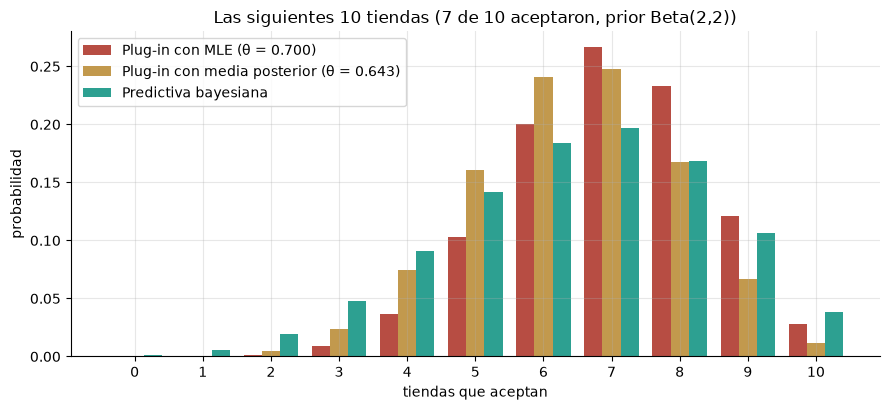

,media,desv. est.,P(≤3),P(≥9),intervalo 80%
método,,,,,
Plug-in con MLE (θ = 0.700),7.000,1.449,0.011,0.149,"[5, 9]"
Plug-in con media posterior (θ = 0.643),6.429,1.515,0.029,0.079,"[4, 8]"
Predictiva bayesiana,6.429,1.917,0.074,0.144,"[4, 9]"


In [10]:
a, b, y, n, m = 2, 2, 7, 10, 10
ap, bp = posterior(a, b, y, n)

dists = {
    "Plug-in con MLE (θ = 0.700)": predictiva_plugin(m, y / n),
    f"Plug-in con media posterior (θ = {ap / (ap + bp):.3f})": predictiva_plugin(m, ap / (ap + bp)),
    "Predictiva bayesiana": predictiva_bayes(m, a, b, y, n),
}
graficar(dists, "Las siguientes 10 tiendas (7 de 10 aceptaron, prior Beta(2,2))",
         colores=[WARN, GOLD, TEAL])
resumen(dists, cola_baja=3, cola_alta=9)

**Pregunta 3.1.** El *plug-in* con la media posterior y la predictiva tienen la **misma media**. Entonces, ¿en qué se diferencian, y por qué la diferencia vive en las colas?

**Tu respuesta:**

El plug-in con la media posterior y la predictiva tienen la misma media porque los dos usan el mismo centro y, como resultado, esperan lo mismo. La diferencia está en qué tanto se abren alrededor de ese centro: la predictiva es más ancha porque cuenta el azar de las tiendas, pero también cuenta que no sabe bien cuál es θ. El plug-in se comporta como si ya supiera θ y solo deja el azar. Por eso la diferencia en las colas, donde al abrirse más, la predictiva le da más probabilidad a los extremos. En el centro casi coinciden, pero en las orillas la predictiva no se queda corta.

**Pregunta 3.2.** Arca decide cuánto producto mandar con base en el escenario "9 o más tiendas aceptan" (para no quedarse corto) y cuánto presupuesto de devoluciones reservar con base en "3 o menos aceptan".

1. Comparen cada *plug-in* con la predictiva, cola por cola. ¿Qué decisiones concretas tomaría mal quien use cada uno? ¿Por exceso o por defecto?
2. El *plug-in* con MLE casi le atina a $P(\ge 9)$. Expliquen por qué ese acierto es casualidad: ¿qué dos errores se están compensando? (Pista: comparen su media con la de los otros dos, y luego miren su otra cola.)

**Tu respuesta:**

1. Cola por cola:

En la cola de "9 o más aceptan" (para no quedarse corto con el producto), el plug-in con MLE casi le atina (0.149 contra 0.144), pero el plug-in con la media posterior se queda corto (0.079). Quien lo use mandaría menos producto del que debería y se quedaría sin stock. La predictiva sí da 0.144, o sea que sí manda lo suficiente.
En la cola de "3 o menos aceptan" (para reservar devoluciones), los dos plug-in se quedan cortos (dan 0.011 y 0.029), mientras la predictiva da 0.074. Quien use el plug-in reservaría muy poco presupuesto de devoluciones y se quedaría corto justo cuando más lo necesita. La predictiva reserva más porque no se ciega.

2. Por qué el acierto del MLE en P(≥9) es casualidad:

Porque está cometiendo dos errores que se compensan. El MLE usa un θ más alto que la media posterior, lo que hace que tienda a dar una mayor probabilidad en la cola alta. Pero al mismo tiempo es más angosto que la predictiva (no cuenta que no sabe bien θ), y eso lo empuja a dar menos. Los dos errores se cancelan y por casualidad se acercan a un resultado "normal". 

### 3.2 ¿Y con más datos?

Misma proporción observada (70%), cada vez más visitas.

In [11]:
a, b, m = 2, 2, 10
filas = []
for n in [10, 100, 1000]:
    y = int(0.7 * n)
    pred = predictiva_bayes(m, a, b, y, n)
    plug = predictiva_plugin(m, y / n)
    filas.append({"visitas n": n,
                  "P(≤3) plug-in": plug.cdf(3), "P(≤3) predictiva": pred.cdf(3),
                  "desv. est. plug-in": plug.std(), "desv. est. predictiva": pred.std()})
pd.DataFrame(filas).set_index("visitas n")

,P(≤3) plug-in,P(≤3) predictiva,desv. est. plug-in,desv. est. predictiva
visitas n,,,,
10,0.011,0.074,1.449,1.917
100,0.011,0.016,1.449,1.521
1000,0.011,0.011,1.449,1.457


**Pregunta 3.3.** Con 10 visitas, el *plug-in* le da a "3 o menos" una probabilidad unas siete veces menor que la predictiva. Con 1,000 visitas, prácticamente coinciden. Expliquen por qué, en términos de qué le pasa al posterior. Alguien concluye: "entonces la predictiva solo importa con muestras chiquitas". Guarden esa frase: la siguiente celda la pone a prueba.

**Tu respuesta:**

Con más datos el resultado se va acercando a la idea original que formó la distribución, o sea, el posterior se va cerrando alrededor del valor real y la duda sobre θ se hace cada vez más chica. Con 10 visitas el plug-in no lo toma en cuenta, por eso se queda corto en la cola de "3 o menos". Con 1,000 visitas ya casi no hay duda sobre θ, y por eso la predictiva y el plug-in coinciden. No es que la predictiva deje de servir con muestras grandes, mas bien ocurre que que con muchos datos los dos métodos ya ven casi lo mismo.

### 3.3 ¿De dónde viene la incertidumbre?

La varianza de la predictiva se separa en dos partes (ley de la varianza total):

$$
\text{Var}(\tilde y\mid\text{datos})=\underbrace{m\,\mathbb E[\theta(1-\theta)\mid\text{datos}]}_{\text{azar del conteo}}+\underbrace{m^2\,\text{Var}(\theta\mid\text{datos})}_{\text{no sé }\theta}.
$$

La tabla muestra qué **porcentaje** de la varianza viene de no saber $\theta$, según cuántas visitas tengo ($n$) y cuántas tiendas quiero predecir ($m$).

In [12]:
a, b = 2, 2
tabla = {}
for n in [10, 100, 1000]:
    y = int(0.7 * n)
    fila = {}
    for m in [1, 10, 100, 1000]:
        azar, no_se = descomponer_varianza(a, b, y, n, m)
        fila[f"m = {m}"] = 100 * no_se / (azar + no_se)
    tabla[f"n = {n}"] = fila
print("Porcentaje de la varianza que viene de NO SABER θ:")
pd.DataFrame(tabla).T.round(1)

Porcentaje de la varianza que viene de NO SABER θ:


,m = 1,m = 10,m = 100,m = 1000
n = 10,6.700,41.700,87.700,98.600
n = 100,1.000,8.800,49.000,90.600
n = 1000,0.100,1.000,9.100,49.900


**Pregunta 3.4.** Lean la tabla por renglones y por columnas.

1. Con 1,000 visitas y queriendo predecir 1,000 tiendas, ¿qué parte de la incertidumbre viene de no saber $\theta$? ¿Sigue en pie la frase "la predictiva solo importa con muestras chiquitas"?
2. ¿Por qué una parte crece como $m$ y la otra como $m^2$? Piensen en qué pasa si $\theta$ resulta ser un poco más alto de lo que creían: ¿afecta a una tienda o a todas a la vez?
3. Arca va a lanzar un producto en 2,000 tiendas y le pregunta si vale la pena pagar un piloto más grande. ¿Qué parte de la incertidumbre puede reducir el piloto y cuál no? Usen la tabla para argumentar.

**Tu respuesta:**

1. Con 1,000 visitas y prediciendo 1,000 tiendas, casi toda la incertidumbre (49.9%) viene de no saber θ, aunque el posterior esté bien cerrado. Entonces la frase "la predictiva solo importa con muestras chiquitas" deja de hacer sentido porque importa cuando predices muchas tiendas, aunque tengas muchos datos, porque el no-saber-θ se multiplica por todas a la vez.

2. El azar del conteo crece como m porque cada tienda es un volado independiente. El no-saber-θ crece como m² porque si θ resulta un poco más alto de lo que creías, afecta a todas a la vez.

3. El piloto más grande reduce la parte de "no sé θ" (deja el posterior más cerrado y estima mejor la tasa real), pero no puede reducir el azar del conteo. Entonces el piloto sí vale para la parte de no-saber-θ, pero hay un piso de incertidumbre que no se quita con más datos.


## Parte 4. Cuatro gerentes, cuatro priors

Cuatro gerentes ven los mismos datos con creencias previas distintas:

| Gerente | Prior | Media previa | "Vale" como |
|---|---|---|---|
| Neutral | Beta(1, 1) | 0.50 | 2 visitas |
| Optimista | Beta(8, 2) | 0.80 | 10 visitas |
| Escéptica | Beta(2, 8) | 0.20 | 10 visitas |
| Terco | Beta(60, 40) | 0.60 | 100 visitas |

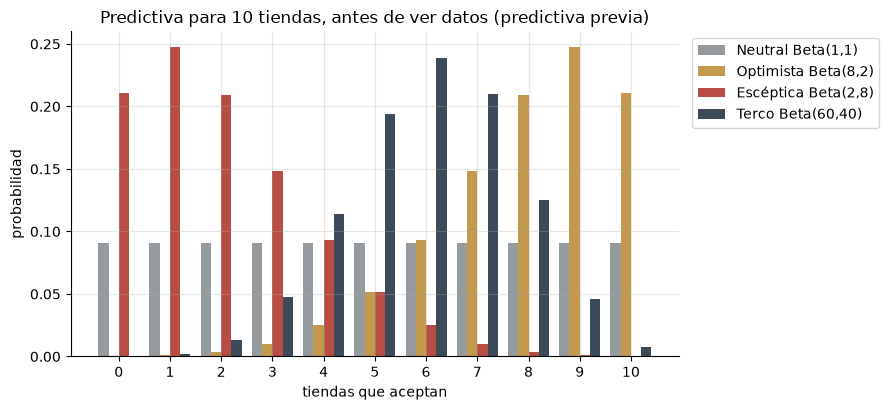

,P(siguiente acepta),media,desv. est.,P(≤3),P(≥9),intervalo 80%
método,,,,,,
"Neutral Beta(1,1)",0.500,5.000,3.162,0.364,0.182,"[1, 9]"
"Optimista Beta(8,2)",0.800,8.000,1.706,0.015,0.458,"[6, 10]"
"Escéptica Beta(2,8)",0.200,2.000,1.706,0.816,0.001,"[0, 4]"
"Terco Beta(60,40)",0.600,6.000,1.617,0.064,0.054,"[4, 8]"


In [13]:
GERENTES = {"Neutral Beta(1,1)": (1, 1), "Optimista Beta(8,2)": (8, 2),
            "Escéptica Beta(2,8)": (2, 8), "Terco Beta(60,40)": (60, 40)}
COLORES_G = [GRIS, GOLD, WARN, SLATE]

def comparar_gerentes(y, n, m=10):
    dists = {g: predictiva_bayes(m, a, b, y, n) for g, (a, b) in GERENTES.items()}
    momento = "antes de ver datos (predictiva previa)" if n == 0 else f"después de ver {y} de {n}"
    graficar(dists, f"Predictiva para {m} tiendas, {momento}", colores=COLORES_G)
    tabla = resumen(dists, cola_baja=3, cola_alta=9)
    tabla.insert(0, "P(siguiente acepta)",
                 [predictiva_bayes(1, a, b, y, n).pmf(1) for a, b in GERENTES.values()])
    return tabla

comparar_gerentes(y=0, n=0)       # predictiva previa: antes de ver datos

**Pregunta 4.1.** Esta es la **predictiva previa** de cada gerente. Si ustedes fueran el director comercial y tuvieran que contratar a uno de los cuatro para un producto del que no se sabe nada, ¿cuál contratarían y cuál les preocuparía? Juzguen las creencias por lo que predicen sobre tiendas, no por los números $a$ y $b$.

**Tu respuesta:**

Contrataría al neutral, porque reparte su creencia por igual justo porque no conoce ni las tiendas ni el producto, y eso me parece lo más acertado cuando no sabes nada, pues da la oportunidad de dejar que los datos hablen. Me preocuparía el terco, porque ofrece una visión demasiado específica para un caso del que no tiene idea y eso es peligroso para un producto nuevo. La optimista y la escéptica también me preocupan un poco: la optimista casi no le deja lugar al rechazo y la escéptica casi no le deja lugar a la aceptación, las dos están sesgadas fuerte hacia un lado antes de ver nada.

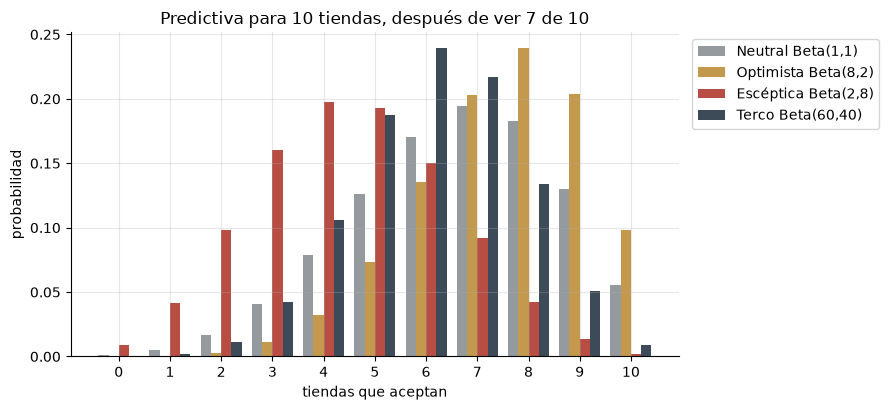

,P(siguiente acepta),media,desv. est.,P(≤3),P(≥9),intervalo 80%
método,,,,,,
"Neutral Beta(1,1)",0.667,6.667,1.939,0.063,0.185,"[4, 9]"
"Optimista Beta(8,2)",0.750,7.500,1.637,0.015,0.302,"[5, 9]"
"Escéptica Beta(2,8)",0.450,4.500,1.880,0.309,0.016,"[2, 7]"
"Terco Beta(60,40)",0.609,6.091,1.604,0.056,0.060,"[4, 8]"


In [14]:
comparar_gerentes(y=7, n=10)

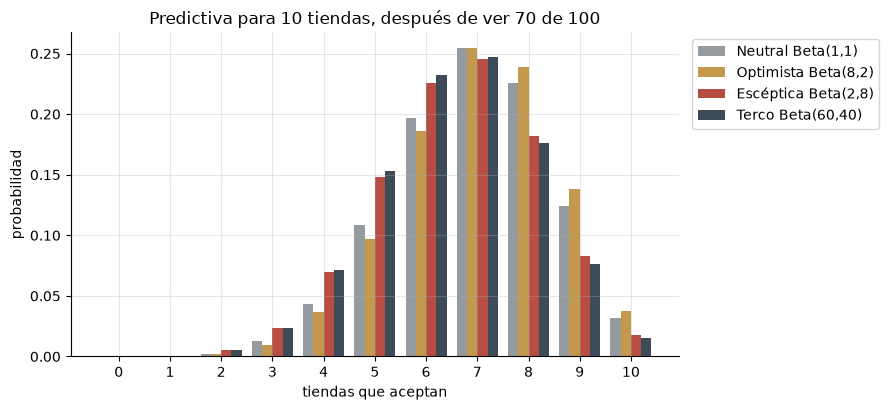

,P(siguiente acepta),media,desv. est.,P(≤3),P(≥9),intervalo 80%
método,,,,,,
"Neutral Beta(1,1)",0.696,6.961,1.517,0.015,0.156,"[5, 9]"
"Optimista Beta(8,2)",0.709,7.091,1.493,0.012,0.176,"[5, 9]"
"Escéptica Beta(2,8)",0.655,6.545,1.563,0.029,0.100,"[5, 9]"
"Terco Beta(60,40)",0.650,6.500,1.542,0.029,0.091,"[4, 8]"


In [15]:
comparar_gerentes(y=70, n=100)

**Pregunta 4.2.** Comparen las dos tablas.

1. Con 10 visitas, ¿quiénes siguen en desacuerdo y por qué?
2. Con 100 visitas, tres de los gerentes casi coinciden. ¿Quién sigue lejos, y por qué precisamente él? (Comparen cuánto "vale" su prior con cuántas visitas hay.)
3. ¿El terco está siendo irracional, o es coherente con lo que dijo creer? ¿Qué tendría que pasar para que cambiara de opinión?

**Tu respuesta:**

1. Con 10 visitas, ¿quiénes siguen en desacuerdo y por qué?

Siguen en desacuerdo casi todos, porque el prior todavía pesa mucho frente a solo 10 visitas. La escéptica es la que más se aleja, pues su prior vale como 10 visitas, o sea, pesa igual que los datos y empuja fuerte hacia 0.2. La optimista también se queda alta porque su prior vale como 10 visitas y la empuja hacia 0.8. El neutral y el terco quedan más cerca del dato.

2. Con 100 visitas, tres casi coinciden. ¿Quién sigue lejos y por qué precisamente él?

Siguen casi coincidiendo neutral, optimista y escéptica porque con 100 visitas los datos ya pesan mucho más que sus priors y a todos los empuja hacia el 0.70 observado. El que sigue lejos es el terco y es justo él porque su prior vale como 100 visitas, este pesa igual que los datos, así que su creencia previa de 0.60 todavía tiene tanto peso como todo lo que vio.

3. ¿El terco es irracional o coherente? ¿Qué tendría que pasar para que cambiara?

No es irracional, más bien lo describiría como coherente con lo que dijo creer. Para que cambie de opinión tendría que ver muchas más visitas que las que "vale" su prior: con 500 o 1,000 visitas su terquedad ya pesaría poco y se acercaría a los demás. Básicamente, el terco no está cerrado a cambiar, solo pide más evidencia que los demás porque llegó con más seguridad.

**Pregunta 4.3 (tu turno).** Inventen su propio prior para un producto nuevo de Arca: escriban un par $(a, b)$ en la celda de abajo y justifíquenlo en una o dos frases ("creo que la tasa anda en …, y le doy el peso de … visitas porque …"). Revisen su predictiva previa: ¿se ve razonable en términos de tiendas? Si no, ajústenlo.

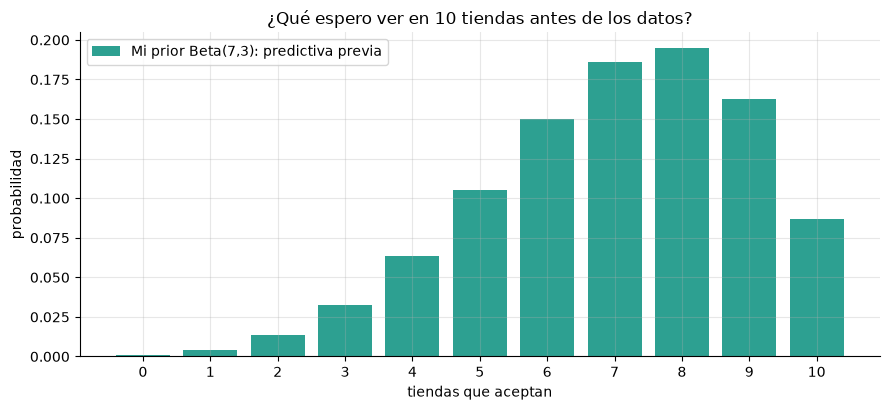

In [19]:
a_mio, b_mio = 7, 3          # Mis cambios

d = predictiva_bayes(10, a_mio, b_mio, y=0, n=0)
graficar({f"Mi prior Beta({a_mio},{b_mio}): predictiva previa": d},
         "¿Qué espero ver en 10 tiendas antes de los datos?", colores=[TEAL])

**Tu respuesta:**

Elegí Beta(7,3) porque creo que la tasa de aceptación está alrededor de 0.70 (espero que 7 de cada 10 tiendas acepten) y le doy el peso de unas 10 visitas. El razonamiento detrás de ello es el siguiente: si bien es un producto nuevo del que no se tienen datos, sí se tiene como punto de partida la reputación de Arca que, al ser una empresa tan bien consolidada, se puede esperar que tenga una introducción de productos con buen ínidce de aceptación.


## Parte 5. ¿Quién predice mejor?

Hasta ahora hemos *argumentado* que la predictiva es más honesta. Ahora lo vamos a **medir**.

**El experimento.** Simulamos 20,000 productos. De cada uno vemos $n$ visitas y predecimos cuántas de las siguientes 10 tiendas aceptan, con un intervalo central del 80%. Luego simulamos lo que de verdad pasa y revisamos tres cosas:

- **promete**: la probabilidad que el propio método le asigna a su intervalo (por ser conteos, casi nunca es exactamente 80%; por eso comparamos contra lo que cada método promete);
- **cumple**: la fracción de veces que el resultado real cayó dentro del intervalo;
- **imposibles**: la fracción de veces que pasó algo a lo que el método le había dado probabilidad **cero**.

Un buen método cumple lo que promete.

Los métodos son: *plug-in* con MLE; *plug-in* "suavizado" con la regla de Laplace, $\hat\theta=\frac{y+1}{n+2}$; y la predictiva bayesiana con tres priors.

In [20]:
def experimento(generar_theta, n, m=10, R=20_000):
    theta = generar_theta(R)                 # la tasa real de cada producto
    y = rng.binomial(n, theta)               # lo que vemos
    y_futuro = rng.binomial(m, theta)        # lo que de verdad pasa después

    metodos = {
        "Plug-in (MLE)": stats.binom(m, y / n),
        "Plug-in suavizado (Laplace)": stats.binom(m, (y + 1) / (n + 2)),
        "Predictiva, prior Beta(1,1)": stats.betabinom(m, 1 + y, 1 + n - y),
        "Predictiva, prior Beta(2,2)": stats.betabinom(m, 2 + y, 2 + n - y),
        "Predictiva, prior Beta(2,8)": stats.betabinom(m, 2 + y, 8 + n - y),
    }
    filas = []
    for nombre, d in metodos.items():
        lo, hi = d.ppf(0.10), d.ppf(0.90)
        promete = d.cdf(hi) - d.cdf(lo - 1)
        cumple = (y_futuro >= lo) & (y_futuro <= hi)
        imposible = d.pmf(y_futuro) == 0
        filas.append({"método": nombre, "promete": promete.mean(),
                      "cumple": cumple.mean(), "imposibles": imposible.mean()})
    return pd.DataFrame(filas).set_index("método")

### Escenario A: productos variados, pocas visitas

Cada producto tiene su propia tasa, sacada de una $\text{Beta}(2,2)$ (hay productos buenos, malos y regulares). Vemos solo **5 visitas** por producto.

In [21]:
experimento(lambda R: rng.beta(2, 2, size=R), n=5)

,promete,cumple,imposibles
método,,,
Plug-in (MLE),0.945,0.604,0.176
Plug-in suavizado (Laplace),0.918,0.754,0.000
"Predictiva, prior Beta(1,1)",0.912,0.901,0.000
"Predictiva, prior Beta(2,2)",0.861,0.864,0.000
"Predictiva, prior Beta(2,8)",0.884,0.641,0.000


**Pregunta 5.1.** El *plug-in* con MLE promete cerca de 94% y cumple cerca de 60%. Expliquen con sus palabras de dónde sale esa brecha. Luego miren la columna de imposibles: ¿en qué datos concretos (qué valores de $y$) el MLE declara imposibles cosas que después pasan?

**Tu respuesta:**

La brecha nace por lo que no se dice del método: MLE es casi perfecto solo cuando la muestra de datos es muy grande. En el caso del experimento, la muestra es muy pequeña y no es suficiente para que lo prometido por MLE y lo que se cumple tengan valores similares. Como la muestra es chiquita, el MLE se cree la proporción observada como si fuera la verdad exacta, por eso promete valores extremos como, por ejemplo, un intervalo muy angosto y que solo cumple como 60%.

El MLE debe considerar como imposibles los casos donde y=0 (ninguna tienda aceptó) o y=n (todas aceptaron). Ahí concluye que θ=0 o θ=1, y le da probabilidad cero a que las siguientes tiendas hagan lo contrario. Pero en el experimento esas cosas sí pasan, porque el producto tenía una tasa real intermedia y las tiendas futuras no le hicieron caso al MLE.

**Pregunta 5.2.** El *plug-in* suavizado eliminó los imposibles, pero sigue sin cumplir lo que promete. ¿Qué arregló el suavizado y qué no pudo arreglar? (Relaciónenlo con la Pregunta 1.4: ¿qué fuente de incertidumbre sigue ignorando?)

**Tu respuesta:**

El plug-in suavizado también calla algo fundamental para su interpretación: la asimetría y el sesgo de la realidad, es decir, que los diferentes eventos no tienen la misma posibilidad de ocurrir, e ignora la contextualidad del fenómeno a estudiar. A diferencia de lo que promete este método, en la vida real las opciones casi nunca son simétricas. En el experimento se puede observar que elimina los imposibles, pero todavía no logra equiparar lo que promete con lo que cumple, no se atiene a la dinámica de los datos en un contexto real.

**Pregunta 5.3.** La predictiva con prior $\text{Beta}(2,2)$ cumple casi exactamente lo que promete. Pero en este escenario los productos se generaron justamente de una $\text{Beta}(2,2)$. ¿Es trampa? ¿Qué está garantizado "por construcción" cuando el prior coincide con la forma en que el mundo genera los productos, y qué **no** está garantizado en la vida real?

**Tu respuesta:**

No es trampa, al contrario, la idea es encontrar/proponer una distribución que se ajuste a ese "ente" generado de los datos (la población), y si se logra encontrar de manera exacta, entonces vas a encontrar una respuesta ideal para el estudio de tu fenómeno. El problema está en que asumes que, efectivamente, esa distribución corresponde a tu fenómeno; si no es así o cambia, entonces puede que tu predicción no se ajuste y genere problemas. En otras palabras, lo que está garantizado por construcción es que, si tu prior coincide con la forma en que el mundo genera los productos, entonces la predictiva va a cumplir exactamente lo que promete: sus intervalos van a contener el resultado real el porcentaje de veces que dice. Lo que no está garantizado en la vida real es que esa coincidencia exista: nadie te asegura que Arca genere productos de una Beta(2,2), ni que la tasa se quede fija, ni que los productos sean todos igual de independientes.

### Escenarios B, C y D: una tasa fija

Ahora todos los productos tienen la misma tasa real. Esta es la forma frecuentista de evaluar: $\theta$ fijo, datos que se repiten.

In [22]:
print("Escenario B: θ = 0.70, 5 visitas")
display(experimento(lambda R: np.full(R, 0.70), n=5))
print("\nEscenario C: θ = 0.95, 5 visitas")
display(experimento(lambda R: np.full(R, 0.95), n=5))
print("\nEscenario D: θ = 0.70, 50 visitas")
display(experimento(lambda R: np.full(R, 0.70), n=50))

Escenario B: θ = 0.70, 5 visitas


,promete,cumple,imposibles
método,,,
Plug-in (MLE),0.942,0.624,0.163
Plug-in suavizado (Laplace),0.916,0.755,0.000
"Predictiva, prior Beta(1,1)",0.911,0.897,0.000
"Predictiva, prior Beta(2,2)",0.856,0.863,0.000
"Predictiva, prior Beta(2,8)",0.873,0.449,0.000



Escenario C: θ = 0.95, 5 visitas


,promete,cumple,imposibles
método,,,
Plug-in (MLE),0.991,0.665,0.313
Plug-in suavizado (Laplace),0.950,0.857,0.000
"Predictiva, prior Beta(1,1)",0.940,0.985,0.000
"Predictiva, prior Beta(2,2)",0.922,0.858,0.000
"Predictiva, prior Beta(2,8)",0.869,0.012,0.000



Escenario D: θ = 0.70, 50 visitas


,promete,cumple,imposibles
método,,,
Plug-in (MLE),0.894,0.852,0.000
Plug-in suavizado (Laplace),0.898,0.867,0.000
"Predictiva, prior Beta(1,1)",0.889,0.885,0.000
"Predictiva, prior Beta(2,2)",0.891,0.896,0.000
"Predictiva, prior Beta(2,8)",0.890,0.853,0.000


**Pregunta 5.4.** Ahora el mundo **no** sale de ningún prior y aun así la predictiva con priors razonables cumple mucho mejor que el *plug-in* en los escenarios B y C. ¿Eso responde, al menos en parte, la duda de la Pregunta 5.3?

**Tu respuesta:**

Sí, porque la distribución elegida sigue siendo similar a la forma en que se generan los datos, aunque no sea exactamente la misma. La predictiva con priors razonables cumple mucho mejor que el plug-in porque el prior, aun sin ser exacto, no está peleado con la realidad y deja lugar a que θ tome muchos valores y no se ciega como el MLE. 

**Pregunta 5.5.** Miren a la gerente escéptica, prior $\text{Beta}(2,8)$, en el escenario C. Promete casi 87% y cumple alrededor de 1%. Expliquen qué pasó. ¿Qué nos dice esto sobre la afirmación "la predictiva bayesiana siempre es más honesta que el *plug-in*"? Completen la frase: "la predictiva es tan honesta como …".

**Tu respuesta:**

La predictiva es tan honesta como qué tan bien conozcas tu fenómeno, pues en la distribución que asignes recae la incertidumbre. Por ende, si eliges una predictiva que se aleja de la distribución real, vas a obtener resultados muy diferentes de lo que buscas. En el escenario C la escéptica tiene un prior Beta(2,8) que espera 0.2 y pesa como 10 visitas. Con solo 5 visitas, su prior manda más que los datos, así que su predictiva se queda pegada cerca de 0.2 mientras el mundo real está en 0.95. Por eso promete 87% y cumple como 1%, pues está midiendo con una regla que no corresponde al fenómeno.


**Pregunta 5.6.** En el escenario D, con 50 visitas, todos los métodos (incluida la escéptica) quedan mucho más cerca de cumplir lo que prometen. Conecten con lo que vieron en la Parte 4 y en la sesión 3: ¿cuándo deja de importar el prior, y cuándo deja de importar la diferencia entre *plug-in* y predictiva? ¿Son la misma condición?

**Tu respuesta:**

Con 50 visitas los métodos se acercan a cumplir porque al tener más iteraciones, los datos empiezan a pesar mucho más que el prior. Con 50 visitas, el prior de la escéptica (que vale como 10) ya pesa poco al lado de los datos, así que su creencia previa deja de mandar y se acerca a lo que dicen los datos. De ahí que los métodos empiecen a cumplir lo que prometen. 

El prior deja de importar cuando hay suficientes datos que lo desvanezcan. La diferencia entre plug-in y predictiva deja de importar cuando el posterior se cierra tanto que ya casi no hay duda sobre θ. Entonces, en reumen, el prior deja de importar cuando los datos lo superan en peso, mientras que el plug-in y la predictiva coinciden cuando el posterior está tan cerrado que la incertidumbre sobre θ casi desaparece.

**Pregunta 5.7 (tu turno).** Diseñen su propio escenario cambiando la tasa real y el número de visitas en la celda de abajo. Busquen uno donde el *plug-in* quede bien parado y otro donde quede muy mal. Reporten los dos y expliquen qué los distingue.

In [ ]:
# theta_real, n_visitas = 0.50, 50          # Mis cambios para un buen resultado
theta_real, n_visitas = 0.95, 5             # Mis cambios para un mal resultado
experimento(lambda R: np.full(R, theta_real), n=n_visitas)



,promete,cumple,imposibles
método,,,
Plug-in (MLE),0.991,0.670,0.309
Plug-in suavizado (Laplace),0.950,0.857,0.000
"Predictiva, prior Beta(1,1)",0.940,0.987,0.000
"Predictiva, prior Beta(2,2)",0.922,0.858,0.000
"Predictiva, prior Beta(2,8)",0.869,0.011,0.000


**Tu respuesta:**

* Escenario bueno (θ = 0.50, 50 visitas): El plug-in promete 0.887 y cumple 0.843, sin imposibles. Queda cerca de los demás porque θ no está pegado a los extremos y con 50 visitas el MLE ya estima bien la tasa.

* Escenario malo (θ = 0.95, 5 visitas): El plug-in queda muy mal, ya que promete 0.991 y solo cumple 0.670, y además tiene 30.9% de imposibles. En este ejemplo el método declara imposible el rechazo dado lo que ve, pero luego las tiendas futuras sí rechazan, y el resultado real se le escapa. El suavizado y las predictivas con priors razonables lo hacen mucho mejor porque no se ciegan con el cero.

* Lo que los distingue es la combinación de θ pegado a los extremos y pocas visitas. MLE se cree la proporción observada como verdad exacta, declara imposibles cosas que pasan y promete mucho más de lo que cumple. Cuando θ está en el centro y hay muchas visitas, el MLE ya estima bien y el plug-in queda bien parado.



> **Nota de justicia.** El *plug-in* es lo que hace casi cualquier tablero, pero no es "lo que hacen los frecuentistas" en general. La estadística frecuentista tiene sus propios **intervalos de predicción**, que sí intentan cargar con la incertidumbre de la estimación. Lo que comparamos aquí es la práctica ingenua de meter $\hat\theta$ como si fuera la verdad, que es la más común en la industria.


## Parte 6. Cierre

**Pregunta 6.1.** Expliquen a un gerente de Arca, en no más de cuatro frases y sin una sola fórmula, por qué su tablero debería mostrar la predictiva y no la tasa observada multiplicada por el número de tiendas.

**Tu respuesta:**

Debería mostrar la predictiva porque es la que tiene una visión más amplia, reconoce sus limitaciones (la tasa observada) respecto a la verdad exacta y da pie a que las siguientes tiendas se comporten distinto (como en la vida real). Si tuvieras que tomar una decisión informada, ¿prefieres hacerlo con una sola carta o con la baraja completa? El plug-in te da un solo número y te hace sentir seguro cuando no lo estás, mientras que la predictiva te muestra el rango de lo que podría pasar, y eso es justo lo que necesitas para decidir cuánto producto mandar y cuánto reservar para devoluciones.

**Pregunta 6.2.** La predictiva descansa en un supuesto: si supiéramos $\theta$, las tiendas futuras se comportarían como las ya visitadas, e independientes entre sí. Den **dos** situaciones realistas en Arca donde ese supuesto falle (piensen en regiones, formatos de tienda, en tiendas que se enteran del producto por otras, o en un vendedor que va aprendiendo). Para cada una, digan si la predictiva quedaría demasiado confiada o demasiado cautelosa.

**Tu respuesta:**

- Caso 1 (regiones): Las tiendas no son iguales entre sí, tienen condiciones diferentes, las de ciudad y las de carretera no se comportan como la misma población. La predictiva, al tratar todas las tiendas como si vinieran de la misma tasa θ, mezclaría las de ciudad (que pueden aceptar más) con las lejanas (que pueden aceptar menos) y daría un rango que no refleja la diferencia real entre regiones.

- Caso 2 (vendedores que aprenden): Las tendencias de mercado pueden cambiar entre tiendas y el conocimiento de quien las maneja, lo que el vendedor aprende en una tienda o temporada cambia cómo se comporta en la siguiente, y la aceptación depende de la temporada. La predictiva asume que la tasa θ es fija y no cambia con lo que el vendedor aprende ni con la temporada. Si el vendedor ya mejoró, la predictiva seguiría usando la tasa vieja y subestimaría la aceptación real.

**Pregunta 6.3. Defiendan o refuten:** *"Con suficientes datos, el plug-in y la predictiva dan lo mismo; la predictiva es un lujo académico."* Tomen una postura y respondan a la mejor objeción que se les ocurra. La tabla de la Parte 3.3 y el escenario C de la Parte 5 deberían aparecer en su argumento.

**Tu respuesta:**

En parte sí es un lujo académico, ya que en la academia conoces el generador de los datos y puedes asimilarlo porque ya lo conoces, en cambio en la vida real tienes que suponerlo y ahí está la dificultad. Pero cuando aciertas en suponerlo, obtienes resultados mucho más certeros que el plug-in. La frase "con suficientes datos dan lo mismo" es cierta solo a medias, al analizar la tabla de la Parte 3.3 es posible observar que con 1,000 visitas y prediciendo 1,000 tiendas, casi la mitad de la incertidumbre sigue viniendo de no saber θ. Y en el escenario C, la escéptica prometió 87% y cumplió 1%, peor que el plug-in, justo porque falló el supuesto. En resumen, el plug-in también supone, y peor, porque se cree que θ̂ es la verdad exacta. 
